In [7]:
!pip install ultralytics



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [20]:
import os
import json
import shutil
import zipfile
import random
from pathlib import Path

import cv2
import yaml
import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display, Video
from ultralytics import YOLO

In [22]:
SEED = 42
EPOCHS = 20
IMGSZ = 640
BATCH = 16
MODEL_NAME = "yolo11s.pt"
LR0 = 0.003
LRF = 0.01
WEIGHT_DECAY = 0.0005
OPTIMIZER = "AdamW"
WORKERS = 2
DEVICE = 0 if torch.cuda.is_available() else "cpu"

CLASS_NAMES = [
    "fish",
    "jellyfish",
    "penguin",
    "puffin",
    "shark",
    "starfish",
    "stingray"
]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print({
    "model": MODEL_NAME,
    "epochs": EPOCHS,
    "image_size": IMGSZ,
    "batch_size": BATCH,
    "amp": True,
    "optimizer": OPTIMIZER,
    "learning_rate": LR0,
    "final_learning_rate_factor": LRF,
    "weight_decay": WEIGHT_DECAY,
    "workers": WORKERS,
    "device": DEVICE,
    "seed": SEED
})

assert torch.cuda.is_available(), "Enable GPU T4 in Kaggle Notebook Settings."

{'model': 'yolo11s.pt', 'epochs': 20, 'image_size': 640, 'batch_size': 16, 'amp': True, 'optimizer': 'AdamW', 'learning_rate': 0.003, 'final_learning_rate_factor': 0.01, 'weight_decay': 0.0005, 'workers': 2, 'device': 0, 'seed': 42}


In [23]:
INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
DATA_ROOT = WORK_ROOT / "aquarium_coco"
YOLO_ROOT = WORK_ROOT / "aquarium_yolo"

annotation_files = list(INPUT_ROOT.rglob("_annotations.coco.json"))

if not annotation_files:
    zip_files = list(INPUT_ROOT.rglob("*.zip"))
    coco_zip = next(
        (p for p in zip_files if "coco" in p.name.lower()),
        None
    )

    if coco_zip is None:
        raise FileNotFoundError(
            "Upload aquarium_coco.zip as a Kaggle input."
        )

    DATA_ROOT.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(coco_zip, "r") as archive:
        archive.extractall(DATA_ROOT)

    annotation_files = list(
        DATA_ROOT.rglob("_annotations.coco.json")
    )

if not annotation_files:
    raise FileNotFoundError("COCO annotation files were not found.")

DATA_ROOT = annotation_files[0].parent.parent

for split in ["train", "valid", "test"]:
    annotation_path = DATA_ROOT / split / "_annotations.coco.json"
    image_dir = DATA_ROOT / split / "images"

    if not annotation_path.exists():
        raise FileNotFoundError(
            f"Missing annotation file: {annotation_path}"
        )

    if not image_dir.exists():
        raise FileNotFoundError(
            f"Missing image folder: {image_dir}"
        )

    with open(annotation_path, "r") as file:
        data = json.load(file)

    print({
        "split": split,
        "images": len(data["images"]),
        "annotations": len(data["annotations"])
    })

{'split': 'train', 'images': 448, 'annotations': 3324}
{'split': 'valid', 'images': 127, 'annotations': 909}
{'split': 'test', 'images': 63, 'annotations': 582}


In [24]:
YOLO_ROOT.mkdir(parents=True, exist_ok=True)

for split in ["train", "valid", "test"]:
    split_root = DATA_ROOT / split
    image_source = split_root / "images"
    annotation_path = split_root / "_annotations.coco.json"

    image_target = YOLO_ROOT / split / "images"
    label_target = YOLO_ROOT / split / "labels"

    image_target.mkdir(parents=True, exist_ok=True)
    label_target.mkdir(parents=True, exist_ok=True)

    with open(annotation_path, "r") as file:
        data = json.load(file)

    categories = sorted(data["categories"], key=lambda x: x["id"])
    category_names = [c["name"].lower() for c in categories]

    if category_names != CLASS_NAMES:
        raise ValueError(
            f"Unexpected class order: {category_names}"
        )

    category_map = {
        category["id"]: index
        for index, category in enumerate(categories)
    }

    annotations_by_image = {}

    for annotation in data["annotations"]:
        if annotation.get("iscrowd", 0):
            continue

        annotations_by_image.setdefault(
            annotation["image_id"], []
        ).append(annotation)

    converted_boxes = 0
    converted_images = 0

    for image_info in data["images"]:
        image_path = image_source / Path(
            image_info["file_name"]
        ).name

        if not image_path.exists():
            matches = list(
                split_root.rglob(
                    Path(image_info["file_name"]).name
                )
            )
            if not matches:
                continue
            image_path = matches[0]

        image = cv2.imread(str(image_path))

        if image is None:
            continue

        height, width = image.shape[:2]

        target_image = image_target / image_path.name

        if image_path.resolve() != target_image.resolve():
            shutil.copy2(image_path, target_image)

        label_path = label_target / (
            image_path.stem + ".txt"
        )

        lines = []

        for annotation in annotations_by_image.get(
            image_info["id"], []
        ):
            x, y, box_width, box_height = map(
                float, annotation["bbox"]
            )

            x1 = max(0.0, x)
            y1 = max(0.0, y)
            x2 = min(float(width), x + box_width)
            y2 = min(float(height), y + box_height)

            if x2 <= x1 or y2 <= y1:
                continue

            class_id = category_map.get(
                annotation["category_id"]
            )

            if class_id is None:
                continue

            x_center = ((x1 + x2) / 2) / width
            y_center = ((y1 + y2) / 2) / height
            normalized_width = (x2 - x1) / width
            normalized_height = (y2 - y1) / height

            lines.append(
                f"{class_id} {x_center:.6f} "
                f"{y_center:.6f} {normalized_width:.6f} "
                f"{normalized_height:.6f}"
            )

        label_path.write_text("\n".join(lines))

        converted_images += 1
        converted_boxes += len(lines)

    print({
        "split": split,
        "converted_images": converted_images,
        "converted_boxes": converted_boxes
    })

{'split': 'train', 'converted_images': 448, 'converted_boxes': 3324}
{'split': 'valid', 'converted_images': 127, 'converted_boxes': 909}
{'split': 'test', 'converted_images': 63, 'converted_boxes': 582}


In [25]:
data_config = {
    "path": str(YOLO_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": {
        0: "fish",
        1: "jellyfish",
        2: "penguin",
        3: "puffin",
        4: "shark",
        5: "starfish",
        6: "stingray"
    }
}

yaml_path = WORK_ROOT / "data.yaml"

with open(yaml_path, "w") as file:
    yaml.safe_dump(data_config, file, sort_keys=False)

for split in ["train", "valid", "test"]:
    image_count = len(
        list((YOLO_ROOT / split / "images").glob("*"))
    )
    label_files = list(
        (YOLO_ROOT / split / "labels").glob("*.txt")
    )
    box_count = sum(
        len(p.read_text().splitlines())
        for p in label_files
    )

    print({
        "split": split,
        "images": image_count,
        "label_files": len(label_files),
        "boxes": box_count
    })

print(yaml_path.read_text())

{'split': 'train', 'images': 448, 'label_files': 448, 'boxes': 3324}
{'split': 'valid', 'images': 127, 'label_files': 127, 'boxes': 909}
{'split': 'test', 'images': 63, 'label_files': 63, 'boxes': 582}
path: /kaggle/working/aquarium_yolo
train: train/images
val: valid/images
test: test/images
names:
  0: fish
  1: jellyfish
  2: penguin
  3: puffin
  4: shark
  5: starfish
  6: stingray



In [26]:
model = YOLO(MODEL_NAME)

train_results = model.train(
    data=str(yaml_path),
    epochs=20,
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    amp=True,
    seed=SEED,
    deterministic=True,
    optimizer=OPTIMIZER,
    lr0=LR0,
    lrf=LRF,
    weight_decay=WEIGHT_DECAY,
    cos_lr=True,
    warmup_epochs=2.0,
    patience=20,
    workers=WORKERS,
    cache=False,
    close_mosaic=5,
    mosaic=1.0,
    mixup=0.05,
    fliplr=0.5,
    scale=0.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    project=str(WORK_ROOT / "runs"),
    name="aquarium_yolo11s",
    exist_ok=True,
    plots=True,
    verbose=True
)

run_dir = Path(train_results.save_dir)
best_weights = run_dir / "weights" / "best.pt"
last_weights = run_dir / "weights" / "last.pt"

if not best_weights.exists():
    raise FileNotFoundError("Best model weights were not saved.")

trained_model = YOLO(str(best_weights))

print({
    "epochs_requested": EPOCHS,
    "amp": True,
    "best_weights": str(best_weights),
    "last_weights": str(last_weights),
    "training_directory": str(run_dir)
})

results_csv = run_dir / "results.csv"

if results_csv.exists():
    import pandas as pd

    training_history = pd.read_csv(results_csv)
    display(training_history.tail())

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=aquarium_yolo11s, nbs=64, nms=None, opset=None, optimize=False, 

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
15,16,122.066,1.49418,1.52983,1.31435,0.64888,0.49776,0.57605,0.31400,1.60981,1.46813,1.38348,0.000465,0.000465,0.000465
16,17,128.826,1.47097,1.44088,1.28497,0.64971,0.55993,0.60469,0.33359,1.57392,1.33948,1.37018,0.000314,0.000314,0.000314
17,18,135.601,1.44828,1.34698,1.27251,0.69476,0.55180,0.61735,0.33991,1.56523,1.33073,1.36513,0.000192,0.000192,0.000192
18,19,142.355,1.43855,1.33161,1.26668,0.73387,0.56739,0.62365,0.34603,1.56635,1.31605,1.36264,0.000103,0.000103,0.000103
19,20,149.080,1.43124,1.29726,1.25890,0.73451,0.56813,0.62961,0.34985,1.56307,1.29821,1.35919,0.000048,0.000048,0.000048


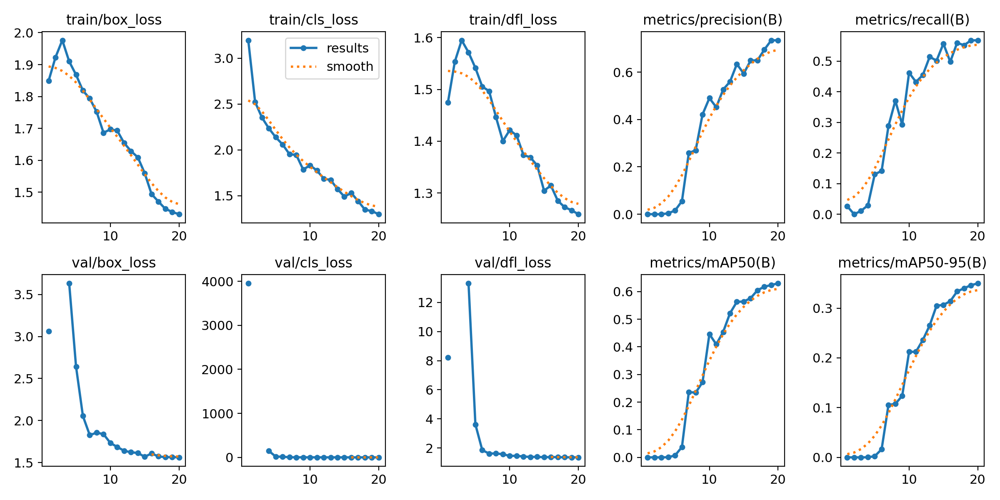

In [27]:
results_plot = run_dir / "results.png"

if results_plot.exists():
    display(Image.open(results_plot))

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,415,509 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2151.0±587.5 MB/s, size: 99.7 KB)
val: Scanning /kaggle/working/aquarium_yolo/test/labels... 63 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 63/63 1.3Kit/s 0.0s
val: New cache created: /kaggle/working/aquarium_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.9it/s 2.1s0.8s
                   all         63        582      0.782      0.602      0.676      0.368
                  fish         30        249      0.772       0.47      0.643      0.372
             jellyfish         11        154      0.828      0.766      0.828       0.51
               penguin          7         82      0.763       0.61      0.702       0.31
                puffin          6         35      0.814  

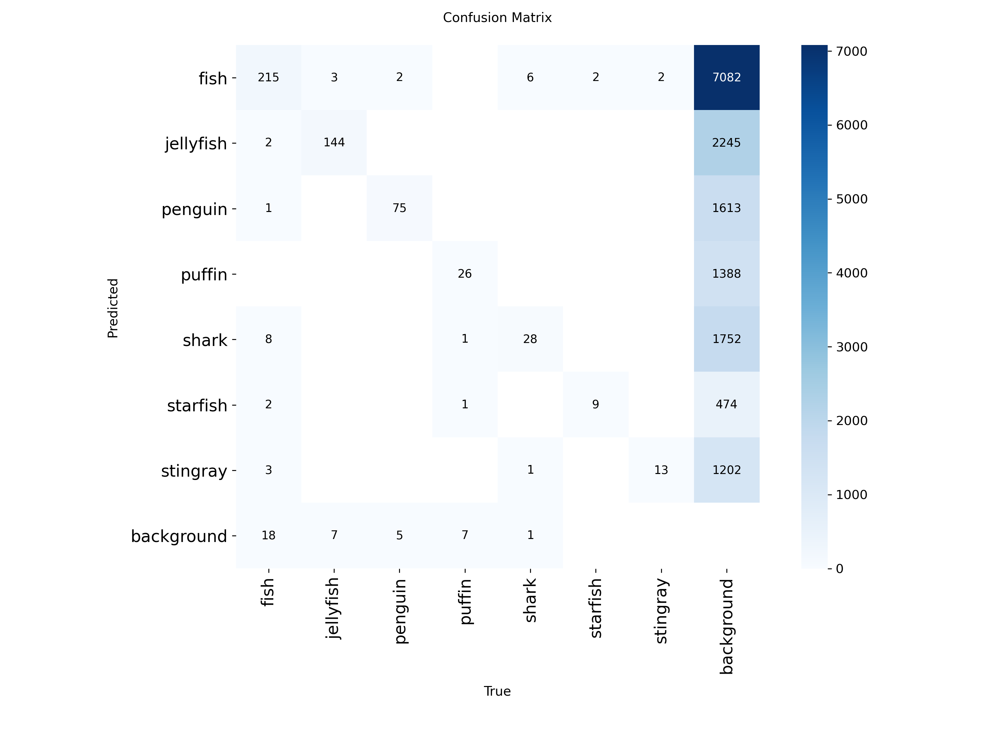

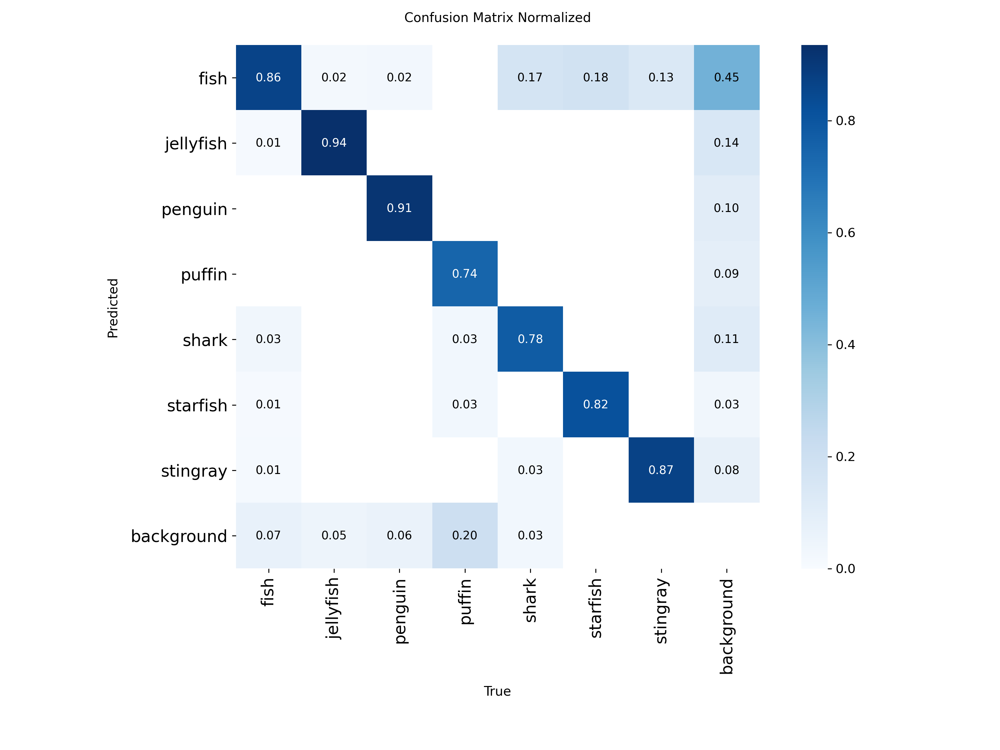

In [28]:
metrics = trained_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    plots=True,
    save_json=True,
    project=str(WORK_ROOT / "runs"),
    name="aquarium_test_evaluation",
    exist_ok=True
)

print("mAP@0.5:", float(metrics.box.map50))
print("mAP@0.5:0.95:", float(metrics.box.map))
print("Precision:", float(metrics.box.mp))
print("Recall:", float(metrics.box.mr))

for index, class_name in enumerate(CLASS_NAMES):
    print(
        class_name,
        "AP@0.5:", float(metrics.box.ap50[index]),
        "AP@0.5:0.95:", float(metrics.box.ap[index])
    )

evaluation_dir = Path(metrics.save_dir)

for plot_name in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png"
]:
    plot_path = evaluation_dir / plot_name

    if plot_path.exists():
        display(Image.open(plot_path))


0: 640x480 (no detections), 9.3ms
1: 640x480 1 jellyfish, 22 penguins, 9.3ms
2: 640x480 7 penguins, 9.3ms
3: 640x480 (no detections), 9.3ms
Speed: 1.5ms preprocess, 9.3ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /kaggle/working/test_predictions


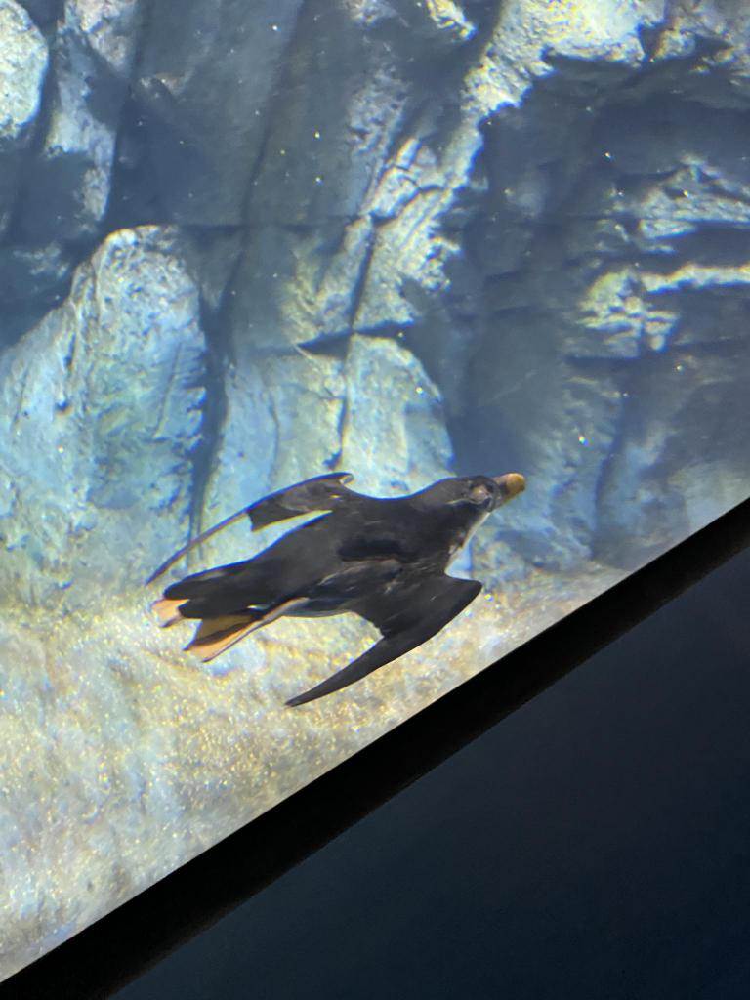

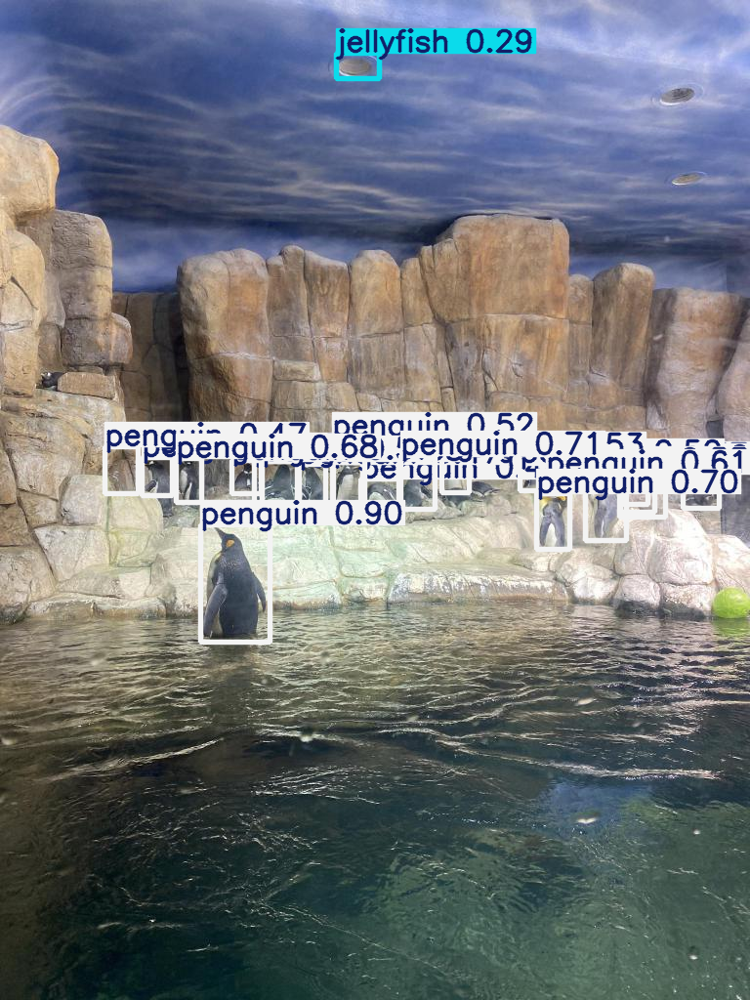

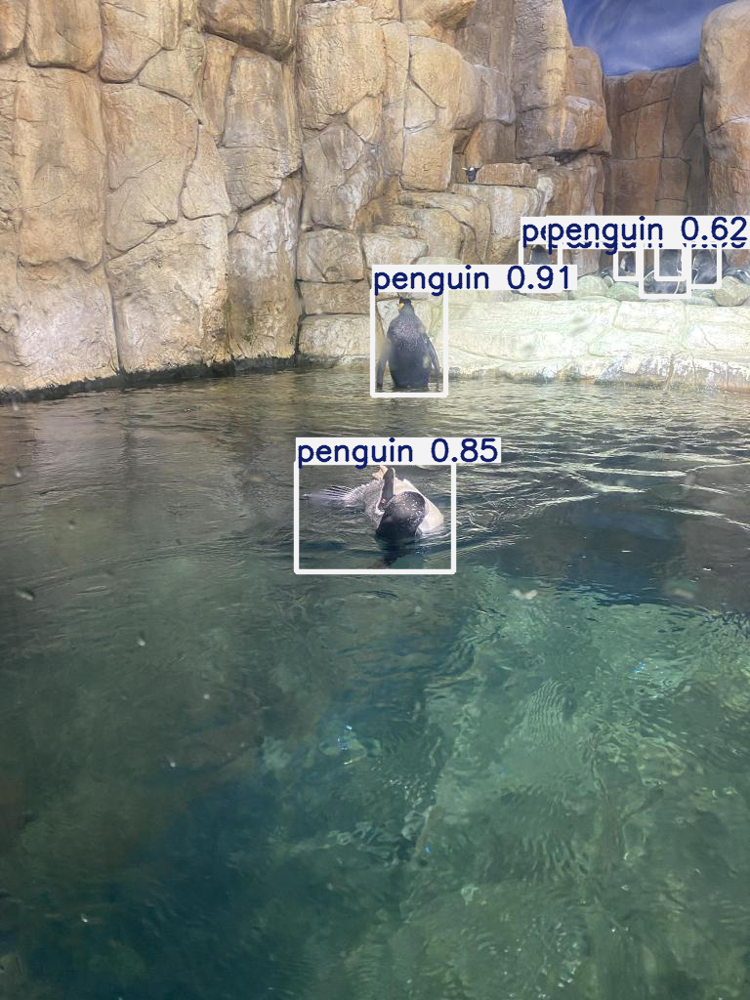

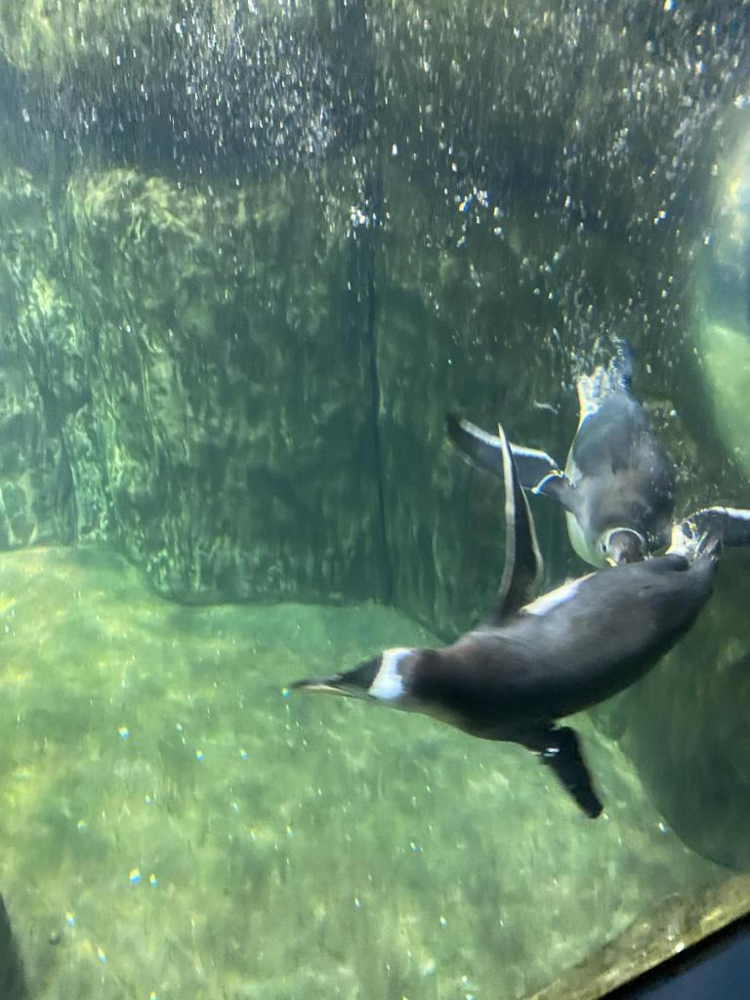

In [29]:
test_image_dir = YOLO_ROOT / "test" / "images"

test_images = sorted([
    p for p in test_image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

if len(test_images) < 4:
    raise ValueError("At least four test images are required.")

prediction_results = trained_model.predict(
    source=[str(p) for p in test_images[:4]],
    imgsz=IMGSZ,
    conf=0.25,
    iou=0.7,
    device=DEVICE,
    save=True,
    project=str(WORK_ROOT),
    name="test_predictions",
    exist_ok=True
)

for result in prediction_results:
    display(Image.fromarray(result.plot()[..., ::-1]))

In [31]:
import os
import shutil
import subprocess
from pathlib import Path
import cv2
from IPython.display import Video, display

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
OUTPUT_VIDEO = WORK_ROOT / "detection.mp4"
TEMP_VIDEO = WORK_ROOT / "detection_temp.avi"

video_files = list(INPUT_ROOT.rglob("test.mp4"))

if not video_files:
    raise FileNotFoundError(
        "test.mp4 not found. Upload it as a Kaggle input dataset."
    )

VIDEO_PATH = video_files[0]
print("Input video:", VIDEO_PATH)

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError(
        "Cannot open input video. Check that test.mp4 is valid."
    )

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if fps <= 0:
    fps = 30.0

if width <= 0 or height <= 0:
    cap.release()
    raise RuntimeError("Invalid video dimensions.")

print({
    "fps": fps,
    "width": width,
    "height": height,
    "total_frames": total_frames
})

writer = cv2.VideoWriter(
    str(TEMP_VIDEO),
    cv2.VideoWriter_fourcc(*"XVID"),
    fps,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not initialize the video writer.")

frame_number = 0

try:
    while True:
        success, frame = cap.read()

        if not success:
            break

        prediction = trained_model.predict(
            source=frame,
            imgsz=640,
            conf=0.25,
            iou=0.7,
            device=DEVICE,
            verbose=False
        )[0]

        annotated_frame = prediction.plot()

        if annotated_frame.shape[:2] != (height, width):
            annotated_frame = cv2.resize(
                annotated_frame, (width, height)
            )

        writer.write(annotated_frame)
        frame_number += 1

        if frame_number % 100 == 0:
            print(f"Processed {frame_number} frames")

finally:
    cap.release()
    writer.release()

if frame_number == 0 or not TEMP_VIDEO.exists():
    raise RuntimeError("No video frames were processed.")

print("Processed frames:", frame_number)

ffmpeg = shutil.which("ffmpeg")

if ffmpeg:
    conversion = subprocess.run(
        [
            ffmpeg, "-y",
            "-i", str(TEMP_VIDEO),
            "-c:v", "libx264",
            "-pix_fmt", "yuv420p",
            "-movflags", "+faststart",
            "-an",
            str(OUTPUT_VIDEO)
        ],
        capture_output=True,
        text=True
    )

    if conversion.returncode != 0:
        print("MP4 conversion failed; using OpenCV MP4 output.")
        cap = cv2.VideoCapture(str(TEMP_VIDEO))
        mp4_writer = cv2.VideoWriter(
            str(OUTPUT_VIDEO),
            cv2.VideoWriter_fourcc(*"mp4v"),
            fps,
            (width, height)
        )

        while True:
            success, frame = cap.read()
            if not success:
                break
            mp4_writer.write(frame)

        cap.release()
        mp4_writer.release()
else:
    cap = cv2.VideoCapture(str(TEMP_VIDEO))
    mp4_writer = cv2.VideoWriter(
        str(OUTPUT_VIDEO),
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    while True:
        success, frame = cap.read()
        if not success:
            break
        mp4_writer.write(frame)

    cap.release()
    mp4_writer.release()

if not OUTPUT_VIDEO.exists() or OUTPUT_VIDEO.stat().st_size == 0:
    raise RuntimeError("detection.mp4 was not created successfully.")

check = cv2.VideoCapture(str(OUTPUT_VIDEO))
output_frames = int(check.get(cv2.CAP_PROP_FRAME_COUNT))
check_fps = check.get(cv2.CAP_PROP_FPS)
check.release()

print({
    "output": str(OUTPUT_VIDEO),
    "size_MB": round(OUTPUT_VIDEO.stat().st_size / (1024 * 1024), 2),
    "processed_frames": frame_number,
    "output_frames": output_frames,
    "output_fps": check_fps
})

assert output_frames > 0, "Output video has no readable frames."

display(Video(str(OUTPUT_VIDEO), embed=False))

Input video: /kaggle/input/datasets/mithilamostofa/yolov11-coco/test.mp4
{'fps': 29.97002997002997, 'width': 1280, 'height': 720, 'total_frames': 900}
Processed 100 frames
Processed 200 frames
Processed 300 frames
Processed 400 frames
Processed 500 frames
Processed 600 frames
Processed 700 frames
Processed 800 frames
Processed 900 frames
Processed frames: 900
{'output': '/kaggle/working/detection.mp4', 'size_MB': 9.89, 'processed_frames': 900, 'output_frames': 900, 'output_fps': 29.97002997002997}


In [45]:
from pathlib import Path
from IPython.display import HTML, display
import base64

video_path = Path("/kaggle/working/detection.mp4")

if not video_path.exists() or video_path.stat().st_size == 0:
    raise FileNotFoundError("detection.mp4 is missing or empty.")

with open(video_path, "rb") as f:
    video_data = base64.b64encode(f.read()).decode("utf-8")

display(HTML(f"""
<video width="800" controls>
    <source src="data:video/mp4;base64,{video_data}" type="video/mp4">
    Your browser does not support MP4 playback.
</video>
"""))